# Proyecto 3: población estelar y evolución química

En este proyecto construimos una población estelar sintética mediante métodos de Monte Carlo, con el objetivo de estudiar algunas propiedades de las estrellas de la Vía Láctea y su evolución química.

La simulación asigna a cada estrella una masa inicial y un tiempo de nacimiento. A partir de estas propiedades estimamos su edad actual y determinamos si permanece en la secuencia principal o si ha evolucionado hacia un remanente estelar: enana blanca, estrella de neutrones o agujero negro.

Además, incorporamos un modelo de evolución química para calcular la metalicidad del gas en el momento de formación de cada estrella. Primero estudiamos el escenario de caja cerrada y luego exploramos cómo cambia el enriquecimiento químico al permitir la entrada de gas.

Finalmente, comparamos la distribución de metalicidades de las estrellas simuladas con la muestra observacional de Haywood (2001), prestando especial atención a las estrellas de tipo G y al problema de las enanas G (G-dwarf problem).


In [4]:
%pip install scipy astropy astroquery

el IMF describe cómo se distribuyen las masas de las estrellas al momento de su formación. En este parte utilizamos la IMF de Kroupa (2001), que se representa mediante una ley de potencia por tramos.

Para generar las masas utilizamos el método de transformación inversa. Primero calculamos la probabilidad asociada a cada segmento de la distribución y luego transformamos números aleatorios uniformes en masas que siguen la IMF elegida.

La implementación se divide en funciones que permiten integrar cada tramo de la distribución, calcular su probabilidad relativa y generar las masas aleatorias. También construimos la función de densidad y la distribución acumulada teóricas, que utilizaremos posteriormente para comprobar que el muestreo reproduce correctamente el modelo.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.stats import ks_2samp
import csv
import json

OUT = Path("resultados_mc")
DATA = Path("datos_mc")
OUT.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)
PARAM = dict(N=100_000, seed=42, m_min=0.08, m_break=0.5,
             m_max=100.0, alpha_low=1.3, alpha_high=2.3,
             T_Gyr=10.0, lifetime_norm_Gyr=10.0, lifetime_exponent=-2.5)
rng = np.random.default_rng(PARAM['seed'])
PARAM.update(
    ns_radius_km=12.0,
    f_ej=0.9,
    seed_remnants=2026,
    convergence_seeds=[42, 43, 44, 45, 46],
    infall_fraction=0.8,
    infall_taus_Gyr=[2.0, 7.0],
    g_mass_min=0.8,
    g_mass_max=1.05,
    poor_threshold=-0.5,
    mdf_bin_width=0.1,
)

Referencia de la IMF: [Kroupa (2001), MNRAS 322, 231](https://arxiv.org/abs/astro-ph/0009005).

In [7]:
def power_integral(a, b, alpha):
    
    if np.isclose(alpha, 1.0):
        return np.log(np.asarray(b) / a)
    gamma = 1.0 - alpha
    return (np.asarray(b)**gamma - a**gamma) / gamma


def inverse_power(u, a, b, alpha):
    
    if np.isclose(alpha, 1.0):
        return a * (b/a)**u
    gamma = 1.0 - alpha
    return ((1-u)*a**gamma + u*b**gamma)**(1/gamma)


def kroupa_weights(p):
    
    a, mb, z = p['m_min'], p['m_break'], p['m_max']
    if not 0 < a < mb < z:
        raise ValueError('Se requiere 0 < m_min < m_break < m_max')
    k = mb**(p['alpha_high']-p['alpha_low'])
    weights = np.array([power_integral(a, mb, p['alpha_low']),
                        k*power_integral(mb, z, p['alpha_high'])])
    return k, weights, weights/weights.sum()


def sample_kroupa(N, p, rng):
    
    _, _, probs = kroupa_weights(p)
    u = rng.random(N)
    low = u < probs[0]
    mass = np.empty(N)
    mass[low] = inverse_power(u[low]/probs[0], p['m_min'],
                             p['m_break'], p['alpha_low'])
    mass[~low] = inverse_power((u[~low]-probs[0])/probs[1],
                              p['m_break'], p['m_max'], p['alpha_high'])
    return mass


def kroupa_pdf(m, p):
    
    m = np.asarray(m, dtype=float)
    k, w, _ = kroupa_weights(p)
    out = np.zeros_like(m)
    low = (m >= p['m_min']) & (m < p['m_break'])
    high = (m >= p['m_break']) & (m <= p['m_max'])
    out[low] = m[low]**(-p['alpha_low'])/w.sum()
    out[high] = k*m[high]**(-p['alpha_high'])/w.sum()
    return out


def kroupa_cdf(m, p):
    
    m = np.asarray(m, dtype=float)
    k, w, _ = kroupa_weights(p)
    lower = np.clip(m, p['m_min'], p['m_break'])
    upper = np.clip(m, p['m_break'], p['m_max'])
    return (power_integral(p['m_min'], lower, p['alpha_low']) +
            k*power_integral(p['m_break'], upper, p['alpha_high']))/w.sum()

k, weights, probabilities = kroupa_weights(PARAM)
print('Probabilidades de los segmentos:', probabilities)
print('Suma:', probabilities.sum())

Probabilidades de los segmentos: [0.76070709 0.23929291]
Suma: 1.0


## 2. Comprobación de las masas

Una vez generada la población, comprobamos que las masas obtenidas cumplen los límites definidos para la IMF y que el número de estrellas coincide con el solicitado, es decir, Comparamos las masas generadas con la distribución de Kroupa, usando un histograma y la distribución acumulada.

`m_sorted` contiene las masas ordenadas. `F_empirica` indica la fracción de estrellas con masa menor o igual a cada valor. `m_grid` contiene las masas donde evaluamos la curva teórica.


P(M <= 0.5): teoría=0.760707, muestra=0.760680, sigma=0.001349, diferencia/sigma=-0.02
P(M <= 1): teoría=0.902962, muestra=0.902660, sigma=0.000936, diferencia/sigma=-0.32
P(M <= 8): teoría=0.993728, muestra=0.993740, sigma=0.000250, diferencia/sigma=0.05
Distancia máxima entre CDF: D=0.002993


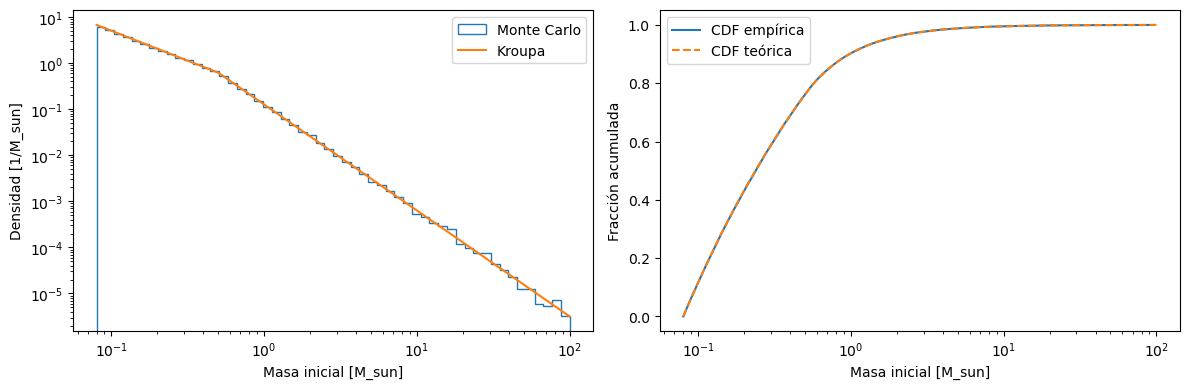

In [9]:
masses = sample_kroupa(PARAM['N'], PARAM, rng)
assert len(masses) == PARAM['N']
assert np.all(np.isfinite(masses))
assert np.all((masses >= PARAM['m_min']) & (masses <= PARAM['m_max']))
assert np.allclose(kroupa_cdf([PARAM['m_min'], PARAM['m_max']], PARAM), [0, 1])

for threshold in [PARAM['m_break'], 1.0, 8.0]:
    expected = float(kroupa_cdf(threshold, PARAM))
    measured = np.mean(masses <= threshold)
    sigma = np.sqrt(expected*(1-expected)/len(masses))
    print(f'P(M <= {threshold:g}): teoría={expected:.6f}, muestra={measured:.6f}, '
          f'sigma={sigma:.6f}, diferencia/sigma={(measured-expected)/sigma:.2f}')

m_sorted = np.sort(masses)
F_empirica = np.arange(1, len(masses)+1)/len(masses)
m_grid = np.geomspace(PARAM['m_min'], PARAM['m_max'], 1000)
F_model = kroupa_cdf(m_sorted, PARAM)
D = max(np.max(F_empirica-F_model),
        np.max(F_model-np.arange(len(masses))/len(masses)))

print(f'Distancia máxima entre CDF: D={D:.6f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(masses, bins=np.geomspace(PARAM['m_min'], PARAM['m_max'], 55),
           density=True, histtype='step', label='Monte Carlo')
ax[0].plot(m_grid, kroupa_pdf(m_grid, PARAM), label='Kroupa')
ax[0].set(xscale='log', yscale='log', xlabel='Masa inicial [M_sun]', ylabel='Densidad [1/M_sun]')
ax[1].plot(m_sorted, F_empirica, label='CDF empírica')
ax[1].plot(m_grid, kroupa_cdf(m_grid, PARAM), '--', label='CDF teórica')
ax[1].set(xscale='log', xlabel='Masa inicial [M_sun]', ylabel='Fracción acumulada')

for a in ax: a.legend()
plt.tight_layout()
fig.savefig(OUT / "validacion_imf.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "validacion_imf.pdf", bbox_inches="tight")
plt.show()

- En el primer gráfico se muestra el histograma de las masas simuladas junto con la densidad teórica de Kroupa. En el segundo se compara la distribución acumulada empírica con la función acumulada teórica.
- En conjunto, estos gráficos permiten evaluar si el procedimiento de muestreo reproduce la IMF adoptada. Una mayor concordancia entre la distribución simulada y la teórica indica que el método de transformación inversa está funcionando adecuadamente. Las pequeñas diferencias que puedan observarse son esperables debido al carácter aleatorio de la simulación.

## 3. Nacimientos y edades

Suponemos una tasa de formación estelar constante durante los $10\text{ Gyr}$ de evolución del modelo. Por esta razón, los tiempos de nacimiento se generan mediante una distribución uniforme entre $0$ y $10\text{ Gyr}$.

A partir del tiempo de nacimiento calculamos la edad actual de cada estrella. Luego estimamos su tiempo de vida en la secuencia principal $t_{\mathrm{MS}}$ utilizando la relación aproximada:

$$
t_{\mathrm{MS}} = 10^{10}\,\mathrm{yr} \left(\frac{M_{\mathrm{initial}}}{M_\odot}\right)^{-2.5}
$$

Comparamos la edad de cada estrella con su tiempo de vida. Si su edad es menor, permanece en la secuencia principal; si es igual o mayor, se considera que ha evolucionado y deberá recibir una asignación de remanente en la siguiente etapa.

También se compara la fracción de estrellas que permanece en la secuencia principal con una estimación teórica obtenida a partir de la IMF y la relación de vida estelar.vida estelar.


is_ms: N=93540, fracción=0.935400
evolved: N=6460, fracción=0.064600
Vida MS de 1 M_sun: 10.0 Gyr
Fracción MS esperada: 0.936243
Fracción MS simulada: 0.935400


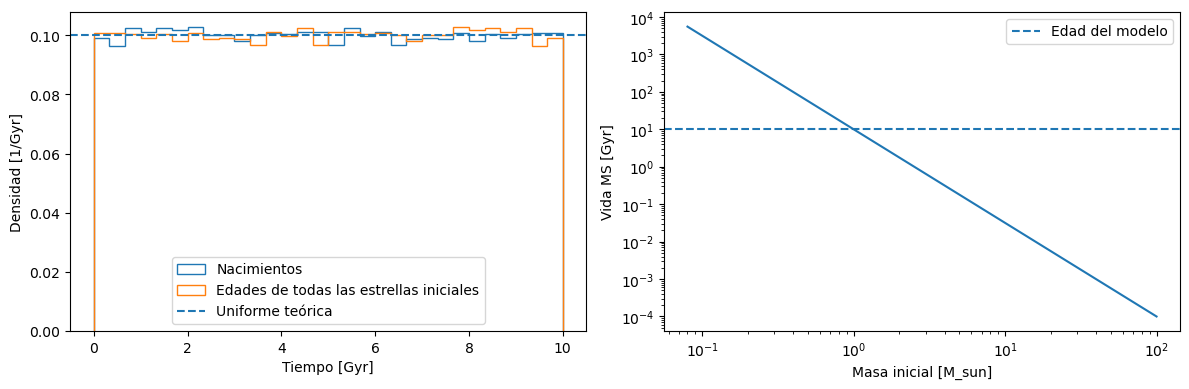

In [11]:
def make_population(masses, p, rng):
    
    birth = rng.uniform(0.0, p['T_Gyr'], len(masses))
    age = p['T_Gyr'] - birth
    lifetime = p['lifetime_norm_Gyr'] * masses**p['lifetime_exponent']
    is_ms = age < lifetime
    return dict(m_initial=masses.copy(), t_birth_Gyr=birth,
                t_age_Gyr=age, t_ms_Gyr=lifetime, is_ms=is_ms,
                evolved=~is_ms)

population = make_population(masses, PARAM, rng)



assert np.allclose(population['t_birth_Gyr'] + population['t_age_Gyr'], PARAM['T_Gyr'])
assert np.all(population['t_ms_Gyr'] > 0)
assert np.all(population['is_ms'] ^ population['evolved'])
for key in ['is_ms', 'evolved']:
    print(f'{key}: N={population[key].sum()}, fracción={population[key].mean():.6f}')
print('Vida MS de 1 M_sun:', PARAM['lifetime_norm_Gyr'], 'Gyr')

prob_ms_grid = np.minimum(PARAM['lifetime_norm_Gyr'] *
                          m_grid**PARAM['lifetime_exponent']/PARAM['T_Gyr'], 1.0)

grids = [np.geomspace(PARAM['m_min'], PARAM['m_break'], 10000),
         np.geomspace(PARAM['m_break'], PARAM['m_max'], 10000)]
trap = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz
expected_ms = sum(trap(kroupa_pdf(g, PARAM)*np.minimum(
    PARAM['lifetime_norm_Gyr']*g**PARAM['lifetime_exponent']/PARAM['T_Gyr'], 1), g)
    for g in grids)
measured_ms = population['is_ms'].mean()
print(f'Fracción MS esperada: {expected_ms:.6f}')
print(f'Fracción MS simulada: {measured_ms:.6f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(population['t_birth_Gyr'], bins=30, density=True, histtype='step', label='Nacimientos')
ax[0].hist(population['t_age_Gyr'], bins=30, density=True, histtype='step', label='Edades de todas las estrellas iniciales')
ax[0].axhline(1/PARAM['T_Gyr'], linestyle='--', label='Uniforme teórica')
ax[0].set(xlabel='Tiempo [Gyr]', ylabel='Densidad [1/Gyr]')
ax[1].plot(m_grid, PARAM['lifetime_norm_Gyr']*m_grid**PARAM['lifetime_exponent'])
ax[1].axhline(PARAM['T_Gyr'], linestyle='--', label='Edad del modelo')
ax[1].set(xscale='log', yscale='log', xlabel='Masa inicial [M_sun]', ylabel='Vida MS [Gyr]')
for a in ax: a.legend()
plt.tight_layout()
fig.savefig(OUT / "nacimientos_y_vida_ms.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "nacimientos_y_vida_ms.pdf", bbox_inches="tight")
plt.show()

- **Gráfico tiempo vs densidad** compara los tiempos de nacimiento con las edades actuales de las estrellas. Debido a que la formación estelar se considera constante, ambas distribuciones deben cubrir el intervalo temporal del modelo. La edad actual se obtiene invirtiendo el tiempo de nacimiento respecto de la edad total de la población.
- **G gráfi Masa inical vs Vida MS**co muestra cómo depende el tiempo de vida en la secuencia principal de la masa inicial. La relación adoptada indica que las estrell s más masivas tienen vidas más cortas. La línea horizontal representa los 10 Gyr de evolución del modelo y permite identificar qué masas tienen tiempos de vida menores que la edad total considerada.

## 4. Modelo Caja cerrada


Para estudiar el enriquecimiento químico de la población utilizamos el modelo de caja cerrada (*closed-box model*). En este escenario suponemos que no existe entrada ni salida de gas, que el material se mezcla instantáneamente y que el rendimiento químico efectivo permanece constante.

La fracción de gas disponible disminuye linealmente con el tiempo, desde un valor inicial igua1 uno hasta una fracción final de 0.10. A partir de esta evolución calculamos la metalicidad del gas mediante la relación de caja cerradcabe mencionar que usamos la evolución del gas dada por la guía; no calculamos el gas devuelto por cada estrella.iento.


Yield efectivo y = 0.00608
Z_gas(0) = 0.0000
Z_gas(T) = 0.0140; Z_sun = 0.014


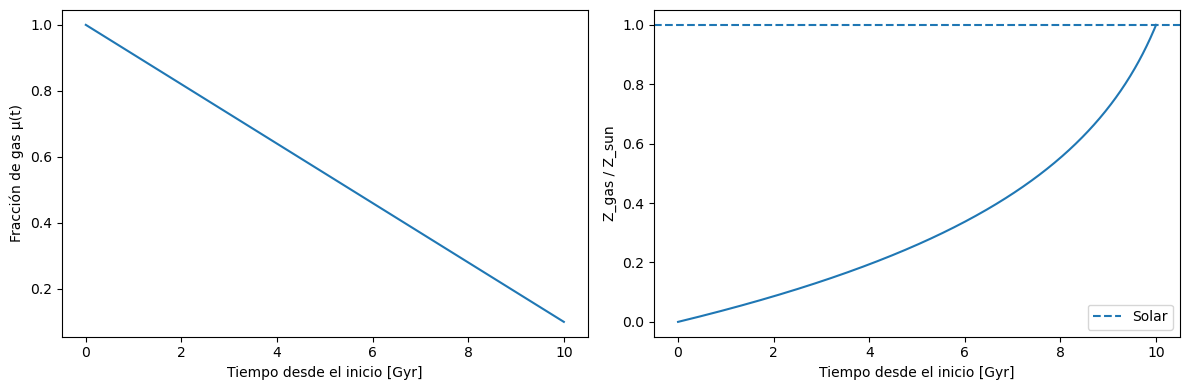

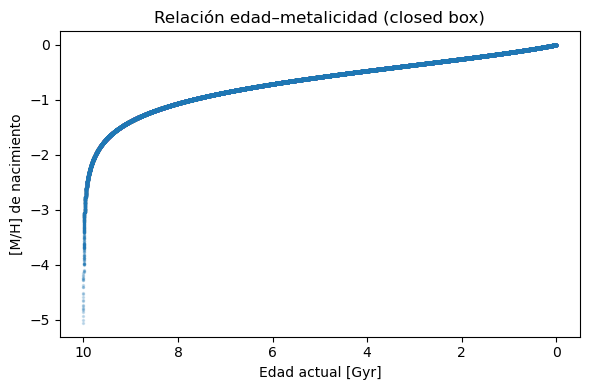

In [13]:

PARAM.update(Z_sun=0.014, mu_final=0.10)

def closed_box_metallicity(t_Gyr, p): 
    t = np.asarray(t_Gyr, dtype=float)
    if np.any((t < 0) | (t > p['T_Gyr'])):
        raise ValueError("Los tiempos deben estar entre 0 y T_Gyr.")
    mu = 1.0 - (1.0 - p['mu_final']) * t / p['T_Gyr']
    yield_eff = p['Z_sun'] / np.log(1.0 / p['mu_final'])
    Z = yield_eff * np.log(1.0 / mu)
    mh = np.full_like(Z, -np.inf, dtype=float)
    positive = Z > 0
    mh[positive] = np.log10(Z[positive] / p['Z_sun'])
    return Z, mh, mu, yield_eff

Z_birth, mh_birth, mu_birth, y_eff = closed_box_metallicity(
    population['t_birth_Gyr'], PARAM)
population.update(Z_birth=Z_birth, mh_birth=mh_birth)
print(f"Yield efectivo y = {y_eff:.5f}")
print(f"Z_gas(0) = {closed_box_metallicity(0., PARAM)[0]:.4f}")
print(f"Z_gas(T) = {closed_box_metallicity(PARAM['T_Gyr'], PARAM)[0]:.4f}; Z_sun = {PARAM['Z_sun']}")
assert np.isclose(closed_box_metallicity(PARAM['T_Gyr'], PARAM)[0], PARAM['Z_sun'])

t_grid = np.linspace(0, PARAM['T_Gyr'], 500)
Z_grid, mh_grid, mu_grid, _ = closed_box_metallicity(t_grid, PARAM)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t_grid, mu_grid)
ax[0].set(xlabel='Tiempo desde el inicio [Gyr]', ylabel='Fracción de gas μ(t)')
ax[1].plot(t_grid, Z_grid / PARAM['Z_sun'])
ax[1].axhline(1, linestyle='--', label='Solar')
ax[1].set(xlabel='Tiempo desde el inicio [Gyr]', ylabel='Z_gas / Z_sun')
ax[1].legend()
plt.tight_layout()
fig.savefig(OUT / "caja_cerrada.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "caja_cerrada.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(population['t_age_Gyr'], population['mh_birth'], s=2, alpha=0.2)
ax.set(xlabel='Edad actual [Gyr]', ylabel='[M/H] de nacimiento',
       title='Relación edad–metalicidad (closed box)')
ax.invert_xaxis()
plt.tight_layout()
fig.savefig(OUT / "edad_metalicidad.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "edad_metalicidad.pdf", bbox_inches="tight")
plt.show()


El primer gráfico muestra la evolución temporal de la fracción de gas y de la metalicidad relativa a la solar. A medida que el gas se transforma en estrellas, su fracción disminuye y la metalicidad del material restante aumenta debido al enriquecimiento químico.

El segundo gráfico presenta la relación edad–metalicidad de nacimiento de las estrellas. Cada punto representa una estrella de la población simulada. Como el modelo supone un enriquecimiento progresivo, las estrellas formadas en épocas más recientes tienden a presentar metalicidades mayores. El eje de edad se invierte para representar visualmente las estrellas más antiguas a la derecha y las más jóvenes a la izquierda.

## 5. Remanentes

Usamos Miller et al. (2026), Full Sample Fit 1, ecuaciones 6–9, para WD. Para NS y BH usamos Raithel et al. (2018): sección 5 y tabla 2 para NS, y ecuaciones 1–4 para BH.

La elección entre NS y BH se sortea según la masa inicial. Tomamos P(BH) = 1 − P(NS), sin un canal separado de fallback.

Entre 8.39 y 9 masas solares extendemos la última recta de WD. Entre 40 y 45 masas solares interpolamos las dos ramas de BH. Estos casos quedan marcados en los datos.

Para NS usamos un radio de 12 km al convertir masa bariónica a gravitacional. Para BH fijamos la fracción de eyección de la envoltura en 0.9. Las estrellas MS mantienen su masa inicial.

No incluimos dependencia con metalicidad ni incertidumbres en los coeficientes WD. Las edades son tiempos desde el nacimiento de la estrella, no edades de enfriamiento del remanente.

El resultado de esta etapa es una clasificación de la población en cuatro categorías: estrellas que permanecen en la secuencia principal (MS), enanas blancas (WD), estrellas de neutrones (NS) y agujeros negros (BH). Para cada objeto también se almacena su masa final o masa del remanente. Esta información permitirá estudiar posteriormente las fracciones de cada tipo de objeto y las distribuciones de masas de la población.


In [15]:
def assign_remnants(pop, p, rng_rem):
    """Devuelve tipo y masa actual/remanente, en M_sun."""
    m = np.asarray(pop["m_initial"], float)
    evolved = np.asarray(pop["evolved"], bool)

    if np.any(evolved & ((m < 0.84) | (m > 120))):
        raise ValueError("Masa evolucionada fuera de 0.84–120 M_sun.")

    f = p["f_ej"]
    radius = p["ns_radius_km"]
    if not (0 <= f <= 1) or radius <= 0:
        raise ValueError("Revisar f_ej y radio NS.")

    kind = np.full(m.size, "MS", dtype="<U2")
    mf = m.copy()
    note = np.full(m.size, "MS", dtype="<U40")

    
    wd = evolved & (m < 9)
    x = m[wd]

    mf[wd] = np.select(
        [x < 1.98, x < 2.33, x < 3.98],
        [
            0.160*x + 0.394,
            -0.155*x + 1.015,
            0.174*x + 0.251,
        ],
        default=0.075*x + 0.644,
    )

    kind[wd] = "WD"
    note[wd] = "Miller"
    note[wd & (m >= 8.39)] = "WD extrapolada 8.39–9"

    
    pns = np.select(
        [
            (m >= 9) & (m < 15),
            (m >= 15) & (m < 17.8),
            (m >= 17.8) & (m < 18.5),
            (m >= 18.5) & (m < 21.7),
            (m >= 25.2) & (m < 27.5),
            (m >= 60) & (m <= 120),
        ],
        [1.0, 0.679, 0.833, 0.500, 0.652, 0.400],
        default=0.0,
    )

    ns = evolved & (~wd) & (rng_rem.random(m.size) < pns)
    bh = evolved & (~wd) & (~ns)

    kind[ns], kind[bh] = "NS", "BH"

    
    x = m[ns]
    mb = np.full(x.size, np.nan)

    j = (x >= 9) & (x <= 13)
    d = x[j] - 14.75
    mb[j] = 2.24 + 0.508*d + 0.125*d**2 + 0.0110*d**3

    j = (x > 13) & (x < 15)
    mb[j] = 0.123 + 0.112*x[j]

    j = (x >= 15) & (x < 17.8)
    mb[j] = 0.996 + 0.0384*x[j]

    j = (x >= 17.8) & (x < 18.5)
    mb[j] = -0.020 + 0.10*x[j]

    j = (x >= 25.2) & (x < 27.5)
    d = x[j] - 2.619
    mb[j] = (
        3232.29 - 409.429*d
        + 17.2867*d**2 - 0.24315*d**3
    )

    for lo, hi, mean, sigma in [
        (18.5, 21.7, 1.60, 0.155),
        (60.0, 121.0, 1.78, 0.016),
    ]:
        j = (x >= lo) & (x < hi)
        draw = rng_rem.normal(mean, sigma, j.sum())

        while np.any(draw <= 0):
            bad = draw <= 0
            draw[bad] = rng_rem.normal(mean, sigma, bad.sum())

        mb[j] = draw

    if np.any(~np.isfinite(mb)) or np.any(mb <= 0):
        raise ValueError("Revisar ramas NS.")

    
    
    s = 1.476625 / radius
    B = 1 + 0.5*s*mb
    mf[ns] = 2*mb / (B + np.sqrt(B**2 + 0.4*s*mb))
    note[ns] = "Raithel NS W18"

    
    def branch1(x):
        d = x - 21.872
        core = -2.024 + 0.4130*x
        whole = (
            16.28 + 0.00694*d
            - 0.05973*d**2 + 0.003112*d**3
        )
        return f*core + (1-f)*whole

    def branch2(x):
        return 5.795 + 1.007e9*x**(-4.926)

    x = m[bh]
    values = np.empty(x.size)

    j = x <= 40
    values[j] = branch1(x[j])

    j = x >= 45
    values[j] = branch2(x[j])

    j = (x > 40) & (x < 45)
    values[j] = np.interp(
        x[j], [40, 45],
        [branch1(40.0), branch2(45.0)],
    )

    mf[bh] = values
    note[bh] = "Raithel BH"
    note[bh & (m > 40) & (m < 45)] = "BH interpolado 40–45"

    assert np.all(np.isfinite(mf) & (mf > 0) & (mf <= m))

    pop["remnant_note"] = note
    return kind, mf


rng_rem = np.random.default_rng(PARAM["seed_remnants"])
kind, m_final = assign_remnants(population, PARAM, rng_rem)
population.update(kind=kind, m_final=m_final)

for label in ["MS", "WD", "NS", "BH"]:
    selected = kind == label
    print(f"{label}: N={selected.sum()}, fracción={selected.mean():.6f}")

print("\nTratamientos utilizados:")
for label, number in zip(*np.unique(
    population["remnant_note"], return_counts=True
)):
    print(label, number)

MS: N=93540, fracción=0.935400
WD: N=5926, fracción=0.059260
NS: N=359, fracción=0.003590
BH: N=175, fracción=0.001750

Tratamientos utilizados:
BH interpolado 40–45 12
MS 93540
Miller 5877
Raithel BH 163
Raithel NS W18 359
WD extrapolada 8.39–9 49


## 6. Convergencia

Repetimos la simulación con cinco semillas. En cada caso generamos un millón de objetos y tomamos los primeros 10², 10³, 10⁴, 10⁵ y 10⁶.

Graficamos la media y la desviación estándar de las fracciones MS, WD, NS y BH. Las muestras de distintos tamaños comparten objetos dentro de cada repetición. La dispersión entre semillas mide el ruido del muestreo.

Usamos generadores separados para masas, nacimientos y remanentes. Con la misma semilla y los mismos parámetros se repite el resultado.


Realización terminada: 42
Realización terminada: 43
Realización terminada: 44
Realización terminada: 45
Realización terminada: 46


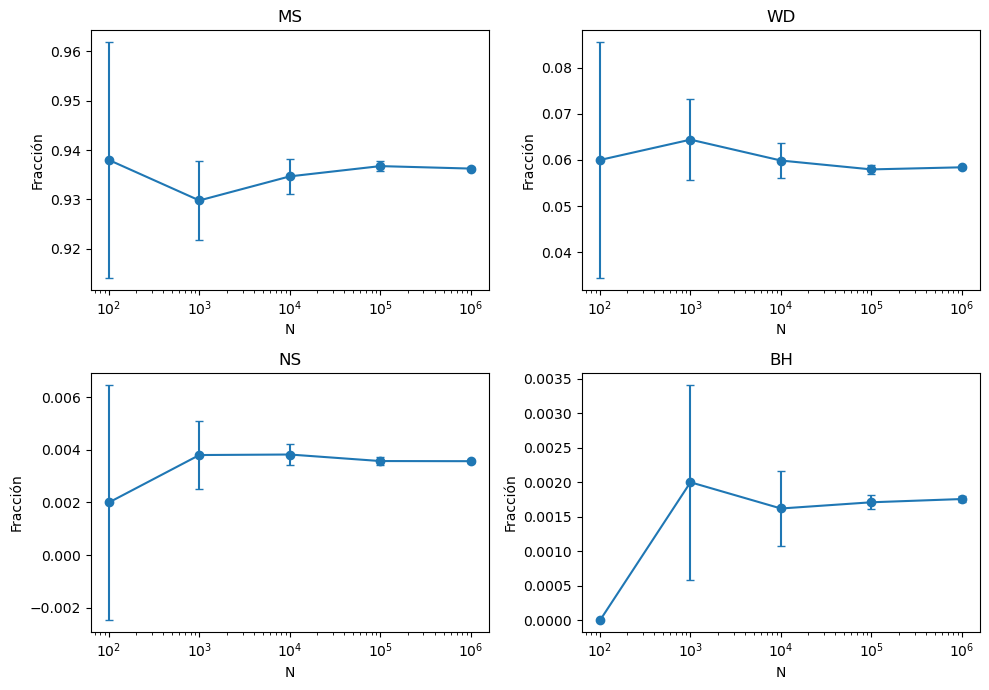

{'N': 1000000, 'tipo': 'MS', 'fraccion_media': 0.9362584, 'dispersion': 0.000313418729497785}
{'N': 1000000, 'tipo': 'WD', 'fraccion_media': 0.058417800000000006, 'dispersion': 0.0002762221931706412}
{'N': 1000000, 'tipo': 'NS', 'fraccion_media': 0.0035667999999999997, 'dispersion': 5.0913652393046797e-05}
{'N': 1000000, 'tipo': 'BH', 'fraccion_media': 0.0017570000000000003, 'dispersion': 3.699324262618783e-05}


In [30]:
def run_population(N, p, seed):
    """Población reproducible; masas M_sun y tiempos Gyr."""
    streams = np.random.SeedSequence(seed).spawn(3)
    rng_mass, rng_time, rng_rem = [
        np.random.default_rng(s) for s in streams
    ]

    mi = sample_kroupa(N, p, rng_mass)
    pop = make_population(mi, p, rng_time)

    z, mh, _, _ = closed_box_metallicity(pop["t_birth_Gyr"], p)
    kind, mf = assign_remnants(pop, p, rng_rem)

    pop.update(
        Z_birth=z, mh_birth=mh,
        kind=kind, m_final=mf,
    )
    return pop


def save_rows(filename, rows):
    """Guarda una lista de diccionarios como CSV."""
    rows = list(rows)
    if not rows:
        raise ValueError("No hay filas para guardar.")

    with open(OUT / filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)



population = run_population(PARAM["N"], PARAM, PARAM["seed"])


test_a = run_population(1000, PARAM, 123)
test_b = run_population(1000, PARAM, 123)
for key in ["m_initial", "t_birth_Gyr", "kind", "m_final"]:
    assert np.array_equal(test_a[key], test_b[key])

N_values = np.array([100, 1000, 10000, 100000, 1000000])
labels = ["MS", "WD", "NS", "BH"]
seeds = PARAM["convergence_seeds"]

fractions = np.empty((len(seeds), len(N_values), len(labels)))

for r, seed in enumerate(seeds):
    pop_max = run_population(int(N_values.max()), PARAM, seed)

    for i, n in enumerate(N_values):
        for j, label in enumerate(labels):
            fractions[r, i, j] = np.mean(
                pop_max["kind"][:n] == label
            )

    print("Realización terminada:", seed)

mean_fraction = fractions.mean(axis=0)
std_fraction = fractions.std(axis=0, ddof=1)

rows = []
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

for j, (label, ax) in enumerate(zip(labels, axes.flat)):
    ax.errorbar(
        N_values, mean_fraction[:, j],
        yerr=std_fraction[:, j], marker="o", capsize=3,
    )
    ax.set(
        xscale="log", xlabel="N",
        ylabel="Fracción", title=label,
    )

    for i, n in enumerate(N_values):
        rows.append(dict(
            N=int(n), tipo=label,
            fraccion_media=float(mean_fraction[i, j]),
            dispersion=float(std_fraction[i, j]),
        ))

save_rows("convergencia.csv", rows)
plt.tight_layout()
plt.savefig(OUT / "convergencia.png", dpi=200)
fig.savefig(OUT / "convergencia.pdf", bbox_inches="tight")
plt.show()

for row in rows:
    if row["N"] == 1000000:
        print(row)


np.savez_compressed(OUT / "poblacion_principal.npz", **population)

Los gráficos muestran cómo cambian las fracciones de MS, WD, NS y BH al aumentar el número de estrellas simuladas, Cada punto representa el promedio obtenido entre las distintas semillas y las barras de error muestran la dispersión entre realizaciones.

Si las fracciones se estabilizan al aumenta\\), significa que las propiedades estadísticas de la población dejan de depender fuertemente de una realización particular. Por el contrario, las fluctuaciones más grandes para muestras pequeñas reflejan el ruido estadístico propio del método Monte Carlo.

Esta comparación permite determinar si el tamaño de la población utilizada en las simulaciones posteriores es suficiente para obtener resultados estadísticamente estables.

## 7. Masas y edades por tipo

En esta sección analizamos cómo se distribuyen las masas iniciales y las edades actuales de las estrellas, separándolas según su estado evolutivo: secuencia principal (MS), enanas blancas (WD), estrellas de neutrones (NS) y agujeros negros (BH).

Primero comparamos las distribuciones de masas iniciales. Esto permite observar qué intervalos de masa dan origen a cada tipo de objeto y cómo influye la IMF en la composición de la población. También comparamos las edades actuales, lo que permite estudiar cómo se relaciona el estado evolutivo con el tiempo transcurrido desde el nacimiento.

Finalmente, construimos la distribución de masas finales. Para las estrellas que permanecen en la secuencia principal, esta masa coincide con la masa inicial, mientras que para los remanentes corresponde a la masa calculada mediante las relaciones de evolución estelar del apartado 5.


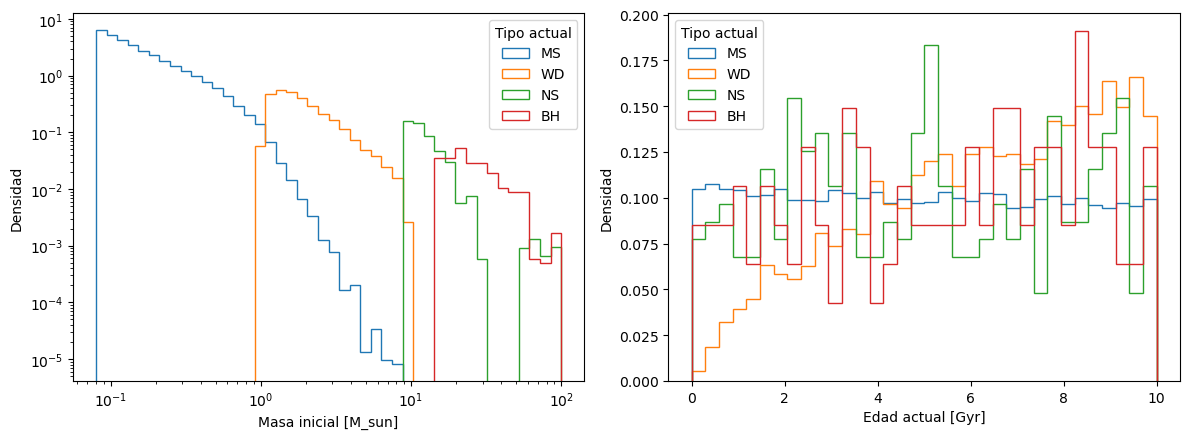

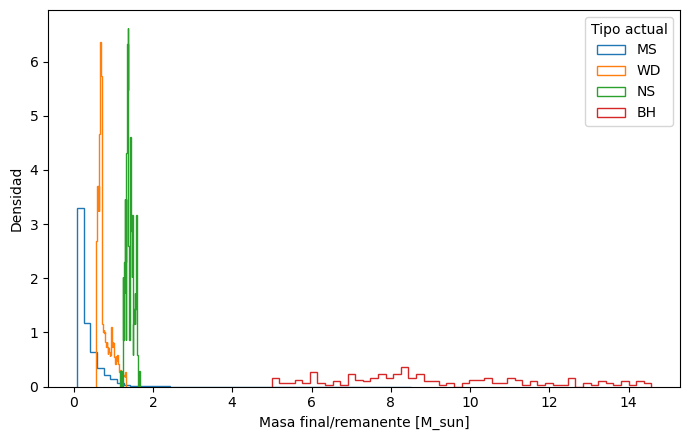

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
bins_m = np.geomspace(PARAM['m_min'], PARAM['m_max'], 45)
for lab in ['MS', 'WD', 'NS', 'BH']:
    sel = population['kind'] == lab
    if np.any(sel):
        ax[0].hist(population['m_initial'][sel], bins=bins_m, histtype='step',
                   density=True, label=lab)
ax[0].set(xscale='log', yscale='log', xlabel='Masa inicial [M_sun]', ylabel='Densidad')
ax[0].legend(title='Tipo actual')
bins_age = np.linspace(0, PARAM['T_Gyr'], 35)
for lab in ['MS', 'WD', 'NS', 'BH']:
    sel = population['kind'] == lab
    if np.any(sel):
        ax[1].hist(population['t_age_Gyr'][sel], bins=bins_age, histtype='step',
                   density=True, label=lab)
ax[1].set(xlabel='Edad actual [Gyr]', ylabel='Densidad')
ax[1].legend(title='Tipo actual')
plt.tight_layout()
fig.savefig(OUT / "masas_iniciales_y_edades.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "masas_iniciales_y_edades.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for lab in ['MS', 'WD', 'NS', 'BH']:
    sel = population['kind'] == lab
    if np.any(sel):
        ax.hist(population['m_final'][sel], bins=50, histtype='step',
                density=True, label=lab)
ax.set(xlabel='Masa final/remanente [M_sun]', ylabel='Densidad')
ax.legend(title='Tipo actual')
plt.tight_layout()
fig.savefig(OUT / "masas_finales.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "masas_finales.pdf", bbox_inches="tight")
plt.show()


los siguientes graficos representan:
- En el primer se observa que los distintos tipos de objetos ocupan regiones diferentes de masa inicial. Las estrellas de mayor masa tienen vidas más cortas y, por lo tanto, tienen mayor probabilidad de haber abandonado la secuencia principal durante los 10 Gyr considerados.

- El segundo muestra las distribuciones de edades actuales. Las diferencias entre las categorías se relacionan con la combinación entre el tiempo de formación y la duración de la vida en secuencia principal.

- El último permite comparar las masas finales de las distintas categorías. En particular, muestra cómo las relaciones inicial–final reducen la masa de las estrellas que evolucionan hacia remanentes. Esta comparación también permite identificar las diferencias entre las prescripciones adoptadas para WD, NS y BH.

## 8. Evolución química con entrada de gas

En el modelo de caja cerrada no existe entrada ni salida de gas. En esta sección modificamos ese supuesto e incorporamos una entrada de gas que disminuye exponencialmente con el tiempo:
$$
A(t)=A_0 e^{-t/\tau}.
$$

Normalizamos las masas a una masa bariónica final de 1. En el modelo
con infall una fracción f_acc llega durante la evolución; inicialmente
hay 1 − f_acc de gas.

Imponemos:

$$
A_0=\frac{f_{\rm acc}}{\tau(1-e^{-T/\tau})}.
$$

La tasa neta de masa retenida en estrellas y remanentes es constante:

$$
L=\frac{1-\mu_f}{T}.
$$

Esta tasa representa el consumo neto de gas después del retorno
instantáneo; no se calcula sumando las pérdidas de masa de cada estrella
simulada.

Para gas entrante sin metales y sin salida de gas:

$$
\frac{dM_g}{dt}=A(t)-L,
$$

$$
\frac{dM_Z}{dt}=yL-ZL,
\qquad Z=\frac{M_Z}{M_g}.
$$

La masa de gas se obtiene integrando la primera ecuación. Resolvemos
numéricamente la ecuación de metales.

Adoptamos f_acc = 0.8 y tau = 2 y 7 Gyr. Son dos escenarios de prueba, sin ajuste a los datos. Conservamos el rendimiento,
la IMF, los nacimientos y las demás propiedades de las mismas estrellas.
Sólo reasignamos la metalicidad según la nueva historia del gas.

El modelo debe recuperar la caja cerrada cuando f_acc = 0. También
comprobamos conservación de masa, balance de metales y sensibilidad
a la tolerancia del integrador.

Los modelos siguen Z total. Para las comparaciones principales adoptamos
[M/H] ≈ [Fe/H], sin calcular Fe y Mg por separado.

Infall_tau2 A0 = 0.4027134619625217 Z_final/Z_sun = 0.9520926782360469
Infall_tau7 A0 = 0.15030692453487218 Z_final/Z_sun = 0.7110501783655813


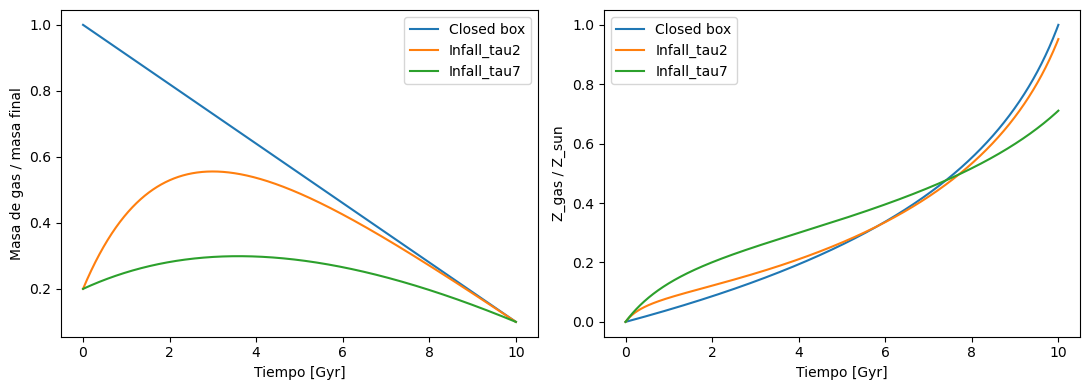

In [35]:
def gas_model(p, f_acc=0.0, tau=2.0, rtol=1e-9):
    """Historia química; masas normalizadas a masa bariónica final = 1."""
    T = p["T_Gyr"]
    mu = p["mu_final"]

    if not (0 <= f_acc < 1 and tau > 0 and 0 < mu < 1):
        raise ValueError("Parámetros químicos inválidos.")

    L = (1-mu) / T
    y = p["Z_sun"] / np.log(1/mu)
    denominator = -np.expm1(-T/tau)
    A0 = f_acc / (tau*denominator)

    def accumulated(t):
        return (
            f_acc * (-np.expm1(-np.asarray(t)/tau))
            / denominator
        )

    def gas(t):
        return 1-f_acc + accumulated(t) - L*np.asarray(t)

    def rhs(t, state):
        mg = gas(t)
        if mg <= 0:
            raise ValueError("La formación estelar agotó el gas.")
        return [y*L - state[0]*L/mg]

    solution = solve_ivp(
        rhs, [0, T], [0.0],
        rtol=rtol, atol=1e-12,
        dense_output=True, max_step=T/200,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    def Z(t):
        t = np.asarray(t, dtype=float)
        if np.any((t < 0) | (t > T)):
            raise ValueError("Tiempo fuera de la simulación.")
        return solution.sol(t)[0] / gas(t)

    return dict(
        Z=Z, gas=gas, accumulated=accumulated,
        L=L, A0=A0, tau=tau, f_acc=f_acc,
    )


times = np.linspace(0, PARAM["T_Gyr"], 2001)
trap = np.trapezoid if hasattr(np, "trapezoid") else np.trapz


zero = gas_model(PARAM, f_acc=0.0)
Z_analytic = closed_box_metallicity(times, PARAM)[0]

assert np.allclose(
    zero["Z"](times), Z_analytic,
    rtol=1e-6, atol=1e-9,
)

histories = {}

for tau in PARAM["infall_taus_Gyr"]:
    h = gas_model(PARAM, PARAM["infall_fraction"], tau)
    fine = gas_model(
        PARAM, PARAM["infall_fraction"], tau,
        rtol=1e-11,
    )

    mg = h["gas"](times)
    z = h["Z"](times)

    assert np.all(mg > 0)
    assert np.all(z >= 0)

    
    assert np.allclose(
        mg + h["L"]*times,
        1-h["f_acc"] + h["accumulated"](times),
    )
    assert np.isclose(h["gas"](PARAM["T_Gyr"]), PARAM["mu_final"])

    
    y = PARAM["Z_sun"] / np.log(1/PARAM["mu_final"])
    produced = y*h["L"]*PARAM["T_Gyr"]
    accounted = mg[-1]*z[-1] + trap(z*h["L"], times)
    assert np.isclose(produced, accounted, atol=2e-7, rtol=1e-5)

    assert np.allclose(
        h["Z"](times), fine["Z"](times),
        rtol=1e-6, atol=1e-9,
    )

    name = f"Infall_tau{tau:g}"
    histories[name] = h

    print(
        name,
        "A0 =", h["A0"],
        "Z_final/Z_sun =", z[-1]/PARAM["Z_sun"],
    )

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

_, _, mu_closed, _ = closed_box_metallicity(times, PARAM)
ax[0].plot(times, mu_closed, label="Closed box")
ax[1].plot(times, Z_analytic/PARAM["Z_sun"], label="Closed box")

for name, h in histories.items():
    ax[0].plot(times, h["gas"](times), label=name)
    ax[1].plot(times, h["Z"](times)/PARAM["Z_sun"], label=name)

ax[0].set(xlabel="Tiempo [Gyr]", ylabel="Masa de gas / masa final")
ax[1].set(xlabel="Tiempo [Gyr]", ylabel="Z_gas / Z_sun")

for a in ax:
    a.legend()

plt.tight_layout()
plt.savefig(OUT / "historias_quimicas.png", dpi=200)
fig.savefig(OUT / "historias_quimicas.pdf", bbox_inches="tight")
plt.show()

El gráfico de la izquierda muestra la evolución de la masa de gas para el modelo de caja cerrada y los dos escenarios con infall. La entrada de gas modifica la cantidad de material disponible durante la evolución y permite comparar cómo influye el tiempo característico $$\tau$$.

El gráfico de la derecha presenta la evolución de la metalicidad del gas en unidades de la metalicidad solar. La entrada de gas sin metales diluye el material enriquecido y modifica la rapidez con la que aumenta la metalicidad.

En nuestra simulación, el modelo con $$\tau=2$$ Gyr termina con una metalicidad de aproximadamente $$0.95,Z_\odot$$, mientras que el modelo con $$\tau=7$$ Gyr alcanza aproximadamente $$0.71,Z_\odot$$. Estos resultados muestran que los parámetros de entrada de gas influyen en la historia de enriquecimiento químico.


## 9. Metalicidades de estrellas de larga vida

Para comparar la distribución de metalicidades simulada con observaciones del vecindario solar, seleccionamos estrellas que permanecen en la secuencia principal y cuya masa inicial cumple:

$$[
0.8 < \frac{M_{\rm initial}}{M_\odot} < 1.05.
]$$

Esta selección permite concentrarnos en estrellas de larga vida, que pueden seguir observándose actualmente y conservar información sobre la composición química del gas en el momento de su formación.

Aplicamos exactamente la misma selección a la población utilizada para los tres escenarios químicos: caja cerrada, infall con tau=2 Gyr e infall con tau=7 Gyr. De esta manera, las diferencias entre las distribuciones obtenidas se deben a la historia de enriquecimiento químico y no a cambios en las masas o los tiempos de nacimiento.

Para cada estrella calculamos la abundancia:

$$[
[M/H]=\log_{10}\left(\frac{Z_{\rm birth}}{Z_\odot}\right).
]$$

Los casos con metalicidad exactamente igual a cero se identifican por separado, ya que corresponden a $$[M/H]=-\infty$$.

In [38]:
def g_selection(pop):
    return (
        pop["is_ms"]
        & (pop["m_initial"] > PARAM["g_mass_min"])
        & (pop["m_initial"] < PARAM["g_mass_max"])
    )


def mdf_values(pop, Z_function=None):
    """[M/H] de la selección de larga vida."""
    selected = g_selection(pop)

    if Z_function is None:
        z = pop["Z_birth"][selected]
    else:
        z = Z_function(pop["t_birth_Gyr"][selected])

    if np.any(~np.isfinite(z)) or np.any(z < 0):
        raise ValueError("Metalicidades inválidas.")

    mh = np.full(len(z), -np.inf)
    positive = z > 0
    mh[positive] = np.log10(z[positive]/PARAM["Z_sun"])

    return mh




population_mdf = run_population(1_000_000, PARAM, PARAM["seed"])

models = {"Closed_box": mdf_values(population_mdf)}

for name, h in histories.items():
    models[name] = mdf_values(population_mdf, h["Z"])

print("Estrellas seleccionadas:", g_selection(population_mdf).sum())

for name, values in models.items():
    print(
        name,
        "fracción pobre =", np.mean(values < PARAM["poor_threshold"]),
        "fracción Z=0 =", np.mean(np.isneginf(values)),
    )

np.savez_compressed(OUT / "mdf_modelos.npz", **models)

Estrellas seleccionadas: 38466
Closed_box fracción pobre = 0.5709977642593459 fracción Z=0 = 0.0
Infall_tau2 fracción pobre = 0.5700358758384028 fracción Z=0 = 0.0
Infall_tau7 fracción pobre = 0.4340196537201685 fracción Z=0 = 0.0


La simulación de un millón de estrellas produce una muestra de 38.466 estrellas que cumplen los criterios de selección.

La fracción con abundancia inferior a -0.5 dex es aproximadamente 57.10 % para la caja cerrada, 57.00 % para el modelo con tau=2 Gyr y 43.40 % para el modelo con tau=7 Gyr.

Estos valores muestran que la historia de entrada de gas modifica la proporción de estrellas pobres en metales. En particular, el escenario con tau=7 Gyr produce una fracción menor que los otros dos escenarios.

## 10. Muestra observacional
Leemos el archivo local haywood.csv y aplicamos el criterio de selección indicado en el catálogo, conservamos las estrellas identificadas con un asterisco en la columna ST y que poseen un valor válido de ([Fe/H]).

La tabla original contiene 348 estrellas. Después de aplicar estos filtros quedan 218 objetos, que constituyen nuestra muestra observacional para la comparación.

El modelo calcula la metalicidad total (Z), mientras que los datos observacionales proporcionan ([Fe/H]). Para realizar la comparación utilizamos la aproximación:

$$[
[M/H]\approx[Fe/H],
]$$

Esta equivalencia debe interpretarse como una aproximación, ya que no estamos calculando por separado la abundancia de hierro y la de otros elementos.

También es importante señalar que la selección observacional no coincide exactamente con nuestro corte de masas y que no aplicamos las correcciones y ponderaciones posteriores discutidas en el artículo original.


In [56]:
from astropy.table import Table

path = DATA / "haywood.csv"

if not path.exists():
    raise FileNotFoundError(
        f"Coloca haywood.csv en: {DATA.resolve()}"
    )

hay = Table.read(path, format="ascii.csv")

assert len(hay) == 348
assert len(np.unique(hay["HIP"])) == 348

st = np.char.strip(
    np.asarray(
        np.ma.filled(np.ma.asarray(hay["ST"]), ""),
        dtype=str,
    )
)

hay_feh = np.asarray(hay["[Fe/H]"], dtype=float)
selected_hay = (st == "*") & np.isfinite(hay_feh)

assert selected_hay.sum() == 218

observations = {"Haywood": hay_feh[selected_hay]}
catalog_status = {
    "Haywood": "tabla 3 extraída del PDF original; lectura local",
    "Adibekyan": "pendiente",
    "GCS": "pendiente",
}

print("Estrellas totales:", len(hay))
print("Estrellas de larga vida:", selected_hay.sum())
print(
    "Fracción con [Fe/H] < -0.5:",
    np.mean(observations["Haywood"] < -0.5),
)

Estrellas totales: 348
Estrellas de larga vida: 218
Fracción con [Fe/H] < -0.5: 0.06880733944954129


In [58]:
from scipy.stats import ks_2samp

required_models = {"Closed_box", "Infall_tau2", "Infall_tau7"}

if not required_models.issubset(models):
    raise RuntimeError(
        "Faltan modelos del apartado 9. "
        f"Disponibles: {list(models)}"
    )

assert len(observations["Haywood"]) == 218

np.savez_compressed(
    OUT / "mdf_observaciones.npz",
    **observations,
)

print("Modelos disponibles:", list(models))
print("Muestra observacional:", len(observations["Haywood"]))

Modelos disponibles: ['Closed_box', 'Infall_tau2', 'Infall_tau7']
Muestra observacional: 218


De las 348 estrellas iniciales, conservamos 218 después de aplicar los criterios establecidos. En esta muestra, aproximadamente el 6.88 % presenta una abundancia ([Fe/H]<-0.5) dex.

Este valor servirá como referencia observacional para evaluar si los modelos químicos reproducen adecuadamente la proporción de estrellas pobres en metales.

## 11. Comparación de metalicidades

En esta sección comparamos las distribuciones de metalicidad obtenidas para los tres modelos químicos con la muestra observacional de Haywood (2001).

Para que la comparación sea consistente, utilizamos los mismos intervalos de metalicidad (bins) en todos los histogramas y normalizamos las distribuciones como densidades de probabilidad.

Además de la comparación visual, calculamos diferentes medidas estadísticas:

Fracción de estrellas pobres en metales, es decir, proporción de estrellas con abundancia inferior a -0.5 dex.

- Mediana: valor central de la distribución.

- Anchura del 68 %: diferencia entre los percentiles 84 y 16.

- Máximo de la distribución: intervalo de metalicidad que contiene el mayor valor del histograma.

- Estadístico KS $$D_{\rm KS}$$: máxima separación entre las funciones de distribución acumulada.

- Distancia de variación total (TV): medida de la diferencia entre las probabilidades de los histogramas.

Estas medidas permiten evaluar distintos aspectos de la comparación. Una distribución puede mejorar en una propiedad y, al mismo tiempo, presentar mayores diferencias en otras.

In [61]:
def common_bins(samples, step):
    """Bins comunes que incluyen todas las abundancias finitas."""
    if step <= 0:
        raise ValueError("El ancho de bin debe ser positivo.")

    finite_parts = []

    for name, values in samples.items():
        x = np.asarray(values, dtype=float)

        if x.ndim != 1 or len(x) == 0:
            raise ValueError(f"Muestra vacía o no unidimensional: {name}")

        if np.any(np.isnan(x)) or np.any(np.isposinf(x)):
            raise ValueError(f"Abundancias inválidas en {name}")

        finite_parts.append(x[np.isfinite(x)])

    finite_values = np.concatenate(finite_parts)

    if len(finite_values) == 0:
        raise ValueError("No hay abundancias finitas.")

    lower_index = int(np.floor(finite_values.min()/step))
    upper_index = int(np.ceil(finite_values.max()/step)) + 1

    return np.arange(lower_index, upper_index + 1) * step


def histogram_probabilities(values, bins):
    """Probabilidad por bin y categoría separada para Z exactamente cero."""
    x = np.asarray(values, dtype=float)

    if x.ndim != 1 or len(x) == 0:
        raise ValueError("MDF vacía o no unidimensional.")

    if np.any(np.isnan(x)) or np.any(np.isposinf(x)):
        raise ValueError("La MDF contiene abundancias inválidas.")

    counts = np.histogram(x[np.isfinite(x)], bins=bins)[0]

    if counts.sum() != np.isfinite(x).sum():
        raise ValueError("Los bins excluyen valores finitos.")

    probabilities = counts / len(x)
    zero_fraction = np.mean(np.isneginf(x))

    assert np.isclose(probabilities.sum() + zero_fraction, 1.0)

    return probabilities, float(zero_fraction)


def mdf_summary(values, bins):
    """Resumen de la MDF; abundancias y anchuras en dex."""
    x = np.asarray(values, dtype=float)
    probabilities, zero_fraction = histogram_probabilities(x, bins)

    poor_fraction = float(np.mean(x < PARAM["poor_threshold"]))

    
    
    if zero_fraction == 0:
        q16, median, q84 = np.quantile(x, [0.16, 0.5, 0.84])
        width68 = q84 - q16
    else:
        median = np.nan
        width68 = np.nan

    peak_index = int(np.argmax(probabilities))

    return dict(
        N=int(len(x)),
        poor_fraction=poor_fraction,
        poor_sigma=float(
            np.sqrt(poor_fraction*(1-poor_fraction)/len(x))
        ),
        median=float(median),
        width68=float(width68),
        peak_lo=float(bins[peak_index]),
        peak_hi=float(bins[peak_index + 1]),
        zeroZ_fraction=zero_fraction,
    )


def compare_mdfs(model, observed, bins):
    """Diferencias descriptivas entre una MDF simulada y la observada."""
    model = np.asarray(model, dtype=float)
    observed = np.asarray(observed, dtype=float)

    p_model, zero_model = histogram_probabilities(model, bins)
    p_observed, zero_observed = histogram_probabilities(observed, bins)

    difference = p_model - p_observed
    largest_index = int(np.argmax(np.abs(difference)))

    
    tv = 0.5 * (
        np.abs(difference).sum()
        + abs(zero_model-zero_observed)
    )

    
    grid = np.unique(np.concatenate([model, observed]))
    cdf_model = (
        np.searchsorted(np.sort(model), grid, side="right")
        / len(model)
    )
    cdf_observed = (
        np.searchsorted(np.sort(observed), grid, side="right")
        / len(observed)
    )
    ks_d = float(np.max(np.abs(cdf_model-cdf_observed)))

    return dict(
        delta_poor=float(
            np.mean(model < PARAM["poor_threshold"])
            - np.mean(observed < PARAM["poor_threshold"])
        ),
        KS_D=ks_d,
        TV=float(tv),
        largest_difference_lo=float(bins[largest_index]),
        largest_difference_hi=float(bins[largest_index + 1]),
        largest_difference=float(difference[largest_index]),
    )


all_samples = {**models, **observations}

bins = common_bins(
    all_samples,
    PARAM["mdf_bin_width"],
)

summary_rows = [
    dict(sample=name, **mdf_summary(values, bins))
    for name, values in all_samples.items()
]

comparison_rows = [
    dict(
        model=model_name,
        observation=obs_name,
        **compare_mdfs(model_values, obs_values, bins),
    )
    for model_name, model_values in models.items()
    for obs_name, obs_values in observations.items()
]


self_comparison = compare_mdfs(
    models["Closed_box"],
    models["Closed_box"],
    bins,
)
assert self_comparison["TV"] == 0
assert self_comparison["KS_D"] == 0


if np.all(np.isfinite(models["Closed_box"])):
    scipy_d = ks_2samp(
        models["Closed_box"],
        observations["Haywood"],
    ).statistic

    our_d = compare_mdfs(
        models["Closed_box"],
        observations["Haywood"],
        bins,
    )["KS_D"]

    assert np.isclose(our_d, scipy_d)

save_rows("resumen_mdf.csv", summary_rows)
save_rows("comparaciones_mdf.csv", comparison_rows)

print("RESUMEN DE LAS DISTRIBUCIONES\n")

for row in summary_rows:
    print(
        f"{row['sample']}: N={row['N']}, "
        f"pobres={100*row['poor_fraction']:.2f} %, "
        f"mediana={row['median']:.3f}, "
        f"anchura68={row['width68']:.3f} dex, "
        f"máximo=[{row['peak_lo']:.2f}, {row['peak_hi']:.2f}]"
    )

print("\nCOMPARACIONES CON HAYWOOD\n")

for row in comparison_rows:
    if row["observation"] == "Haywood":
        print(
            f"{row['model']}: "
            f"Δ fracción pobre={100*row['delta_poor']:+.2f} "
            f"puntos porcentuales, "
            f"D_KS={row['KS_D']:.4f}, "
            f"TV={row['TV']:.4f}"
        )
        print(
            "  Mayor diferencia por bin: "
            f"[{row['largest_difference_lo']:.2f}, "
            f"{row['largest_difference_hi']:.2f}] dex"
        )

RESUMEN DE LAS DISTRIBUCIONES

Closed_box: N=38466, pobres=57.10 %, mediana=-0.583, anchura68=0.940 dex, máximo=[-0.40, -0.30]
Infall_tau2: N=38466, pobres=57.00 %, mediana=-0.571, anchura68=0.735 dex, máximo=[-0.50, -0.40]
Infall_tau7: N=38466, pobres=43.40 %, mediana=-0.459, anchura68=0.484 dex, máximo=[-0.40, -0.30]
Haywood: N=218, pobres=6.88 %, mediana=-0.090, anchura68=0.503 dex, máximo=[0.00, 0.10]

COMPARACIONES CON HAYWOOD

Closed_box: Δ fracción pobre=+50.22 puntos porcentuales, D_KS=0.5688, TV=0.5579
  Mayor diferencia por bin: [0.00, 0.10] dex
Infall_tau2: Δ fracción pobre=+50.12 puntos porcentuales, D_KS=0.5791, TV=0.5703
  Mayor diferencia por bin: [0.00, 0.10] dex
Infall_tau7: Δ fracción pobre=+36.52 puntos porcentuales, D_KS=0.6156, TV=0.6082
  Mayor diferencia por bin: [0.00, 0.10] dex


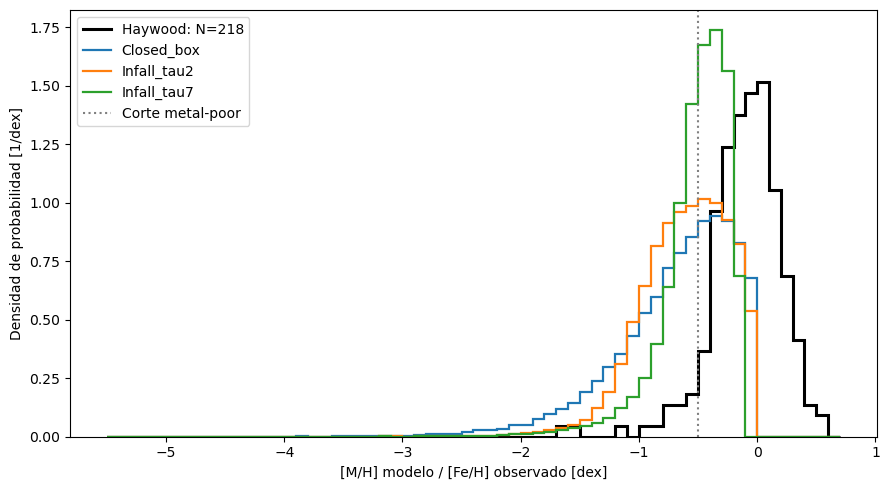

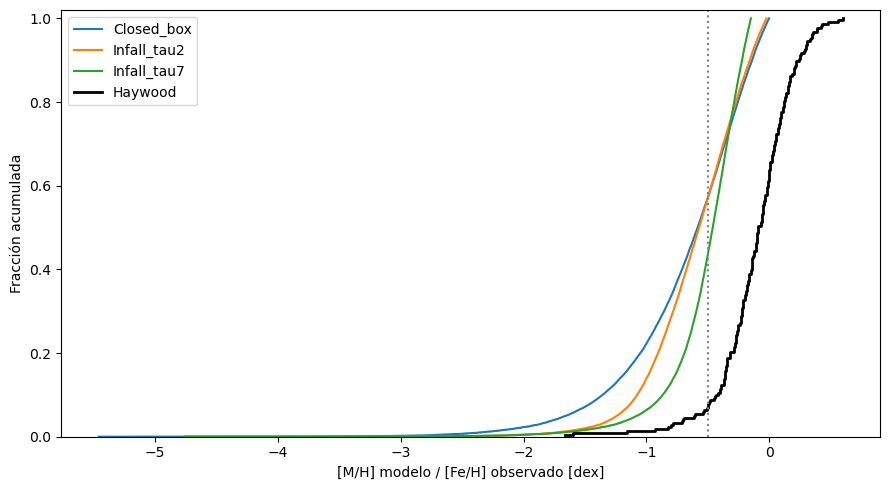

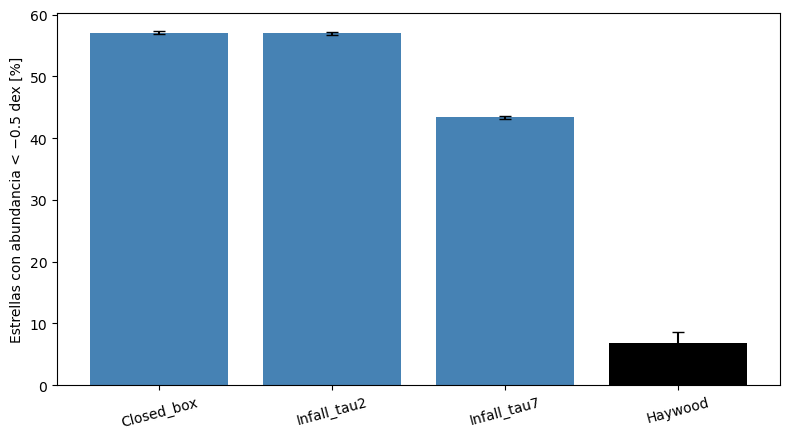

In [63]:
observed = observations["Haywood"]


fig, ax = plt.subplots(figsize=(9, 5))

p_obs, _ = histogram_probabilities(observed, bins)

ax.stairs(
    p_obs/np.diff(bins),
    bins,
    label=f"Haywood: N={len(observed)}",
    color="black",
    linewidth=2.2,
)

for name, values in models.items():
    probabilities, zero_fraction = histogram_probabilities(values, bins)

    ax.stairs(
        probabilities/np.diff(bins),
        bins,
        label=name,
        linewidth=1.6,
    )

    if zero_fraction > 0:
        print(name, "fracción fuera del eje finito por Z=0:", zero_fraction)

ax.axvline(
    PARAM["poor_threshold"],
    color="gray",
    linestyle=":",
    label="Corte metal-poor",
)

ax.set(
    xlabel="[M/H] modelo / [Fe/H] observado [dex]",
    ylabel="Densidad de probabilidad [1/dex]",
)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "MDF_vs_Haywood.png", dpi=200)
fig.savefig(OUT / "MDF_vs_Haywood.pdf", bbox_inches="tight")
plt.show()



fig, ax = plt.subplots(figsize=(9, 5))

for name, values in all_samples.items():
    ordered = np.sort(np.asarray(values, dtype=float))
    cumulative = np.arange(1, len(ordered)+1)/len(ordered)
    finite = np.isfinite(ordered)

    ax.step(
        ordered[finite],
        cumulative[finite],
        where="post",
        label=name,
        color="black" if name == "Haywood" else None,
        linewidth=2 if name == "Haywood" else 1.5,
    )

ax.axvline(
    PARAM["poor_threshold"],
    color="gray",
    linestyle=":",
)

ax.set(
    xlabel="[M/H] modelo / [Fe/H] observado [dex]",
    ylabel="Fracción acumulada",
    ylim=(0, 1.02),
)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "CDF_vs_Haywood.png", dpi=200)
fig.savefig(OUT / "CDF_vs_Haywood.pdf", bbox_inches="tight")
plt.show()



names = [row["sample"] for row in summary_rows]
fractions_poor = [row["poor_fraction"] for row in summary_rows]
errors_poor = [row["poor_sigma"] for row in summary_rows]

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.bar(
    names,
    100*np.asarray(fractions_poor),
    yerr=100*np.asarray(errors_poor),
    capsize=4,
    color=["black" if name == "Haywood" else "steelblue" for name in names],
)

ax.set_ylabel("Estrellas con abundancia < −0.5 dex [%]")
ax.tick_params(axis="x", labelrotation=15)

plt.tight_layout()
plt.savefig(OUT / "fraccion_metal_poor.png", dpi=200)
fig.savefig(OUT / "fraccion_metal_poor.pdf", bbox_inches="tight")
plt.show()


- El primer gráfico compara la densidad de probabilidad de las metalicidades simuladas con la distribución observacional de Haywood. La línea vertical marca el límite de -0.5 dex utilizado para identificar estrellas pobres en metales.

Se observa que los tres modelos producen una proporción de estrellas pobres en metales considerablemente mayor que la muestra observacional. Esto evidencia una diferencia importante entre las predicciones de los modelos y los datos.

- El segundo gráfico muestra la fracción acumulada de estrellas en función de la metalicidad. Esta representación permite comparar las distribuciones completas, sin limitar el análisis a un único intervalo.

La separación entre las curvas indica diferencias en la distribución de metalicidades. El estadístico KS cuantifica la máxima distancia vertical entre dos funciones acumuladas.

- El último gráfico compara directamente el porcentaje de estrellas con abundancia inferior a -0.5 dex. Las barras de error representan la incertidumbre estadística de conteo.

La muestra observacional de Haywood presenta una fracción de estrellas pobres en metales de 6.88 %. En cambio, los modelos obtienen:

Caja cerrada: 57.10 %.

Infall con tau=2 Gyr: 57.00 %.

Infall con tau=7 Gyr: 43.40 %.

Por lo tanto, el modelo con tau=7 Gyr reduce la fracción de estrellas pobres en metales respecto de la caja cerrada y del escenario con tau=2 Gyr. Sin embargo, todavía presenta una diferencia considerable respecto de Haywood.

Los estadísticos KS obtenidos son 0.5688 para la caja cerrada, 0.5791 para el modelo con tau=2 Gyr y 0.6156 para el modelo con tau=7 Gyr. Por su parte, las distancias TV son 0.5579, 0.5703 y 0.6082, respectivamente.

Estos resultados muestran que, aunque el escenario con tau=7 Gyr reduce la fracción de estrellas pobres en metales, no mejora todas las medidas de concordancia con la distribución observacional. En particular, sus valores de KS y TV son mayores.

En consecuencia, no podemos afirmar que la incorporación de infall reproduzca por completo la distribución observada. Los resultados indican que la historia de entrada de gas modifica la MDF, pero que los escenarios explorados todavía presentan discrepancias importantes con los datos.

## 12. Archivos de salida

Se almacenan los parámetros físicos y numéricos utilizados, las semillas aleatorias, las versiones de las bibliotecas y la información sobre la muestra observacional. También guardamos las distribuciones de metalicidad simuladas y observadas en archivos comprimidos.

Entre los principales archivos generados se encuentran:

**parametros.json**: parámetros, versiones de bibliotecas y metadatos de la muestra observacional.

**poblacion_principal.npz**: propiedades de la población estelar simulada.

**mdf_modelos.npz**: distribuciones de metalicidad de los modelos químicos.

**mdf_observaciones.npz**: abundancias de la muestra de Haywood.

**convergencia.csv**: resultados del análisis de convergencia.

**comparaciones_mdf.csv**: comparación estadística entre los modelos y las observaciones.

**resumen_mdf.csv**: resumen de las principales propiedades de las distribuciones.

**Archivos PNG y PDF**: figuras generadas durante el análisis.

El almacenamiento de estos resultados permite separar la etapa de simulación de la etapa de análisis, evitando tener que repetir todos los cálculos cada vez que se desea revisar una figura o una comparación.


In [67]:
import json
import hashlib
import scipy
import matplotlib
import astropy

haywood_path = DATA / "haywood.csv"

metadata = dict(
    parameters=PARAM,
    versions=dict(
        numpy=np.__version__,
        scipy=scipy.__version__,
        matplotlib=matplotlib.__version__,
        astropy=astropy.__version__,
    ),
    observed_samples=list(observations),
    catalog_status=catalog_status,
    haywood_source=dict(
        reference="Haywood 2001, MNRAS 325, 1365",
        source_url="https://arxiv.org/abs/astro-ph/0107077",
        table="Table 3",
        extraction="Texto del PDF; selección por asterisco",
        total_stars=348,
        selected_stars=218,
        additional_selection_corrections=False,
        sha256=hashlib.sha256(haywood_path.read_bytes()).hexdigest(),
    ),
    chemical_models={
        name: dict(
            f_acc=float(h["f_acc"]),
            tau_Gyr=float(h["tau"]),
            A0=float(h["A0"]),
            net_locked_rate=float(h["L"]),
        )
        for name, h in histories.items()
    },
)


def json_default(value):
    """Permite guardar escalares y arrays de NumPy en JSON."""
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    raise TypeError(f"Tipo no serializable: {type(value)}")


with open(OUT / "parametros.json", "w", encoding="utf-8") as f:
    json.dump(
        metadata, f,
        indent=2,
        ensure_ascii=False,
        default=json_default,
    )

np.savez_compressed(
    OUT / "mdf_modelos.npz",
    **models,
)

np.savez_compressed(
    OUT / "mdf_observaciones.npz",
    **observations,
)

print("Productos disponibles:")
for file in sorted(OUT.iterdir()):
    if file.is_file():
        print(file.name)

print("\nCarpeta:", OUT.resolve())

Productos disponibles:
caja_cerrada.pdf
caja_cerrada.png
CDF_vs_Haywood.pdf
CDF_vs_Haywood.png
comparaciones_mdf.csv
convergencia.csv
convergencia.pdf
convergencia.png
diagrama_flujo.pdf
diagrama_flujo.png
edad_metalicidad.pdf
edad_metalicidad.png
fraccion_metal_poor.pdf
fraccion_metal_poor.png
historias_quimicas.pdf
historias_quimicas.png
masas_finales.pdf
masas_finales.png
masas_iniciales_y_edades.pdf
masas_iniciales_y_edades.png
mdf_modelos.npz
mdf_observaciones.npz
MDF_vs_Haywood.pdf
MDF_vs_Haywood.png
nacimientos_y_vida_ms.pdf
nacimientos_y_vida_ms.png
parametros.json
poblacion_principal.npz
resumen_mdf.csv
validacion_imf.pdf
validacion_imf.png

Carpeta: C:\Users\56982\PROYECTO 3 MONTECARLO\resultados_mc


El siguiente diagrama resume las etapas principales de la simulación, desde la definición de los parámetros iniciales hasta la comparación de las distribuciones de metalicidad con los datos observacionales.

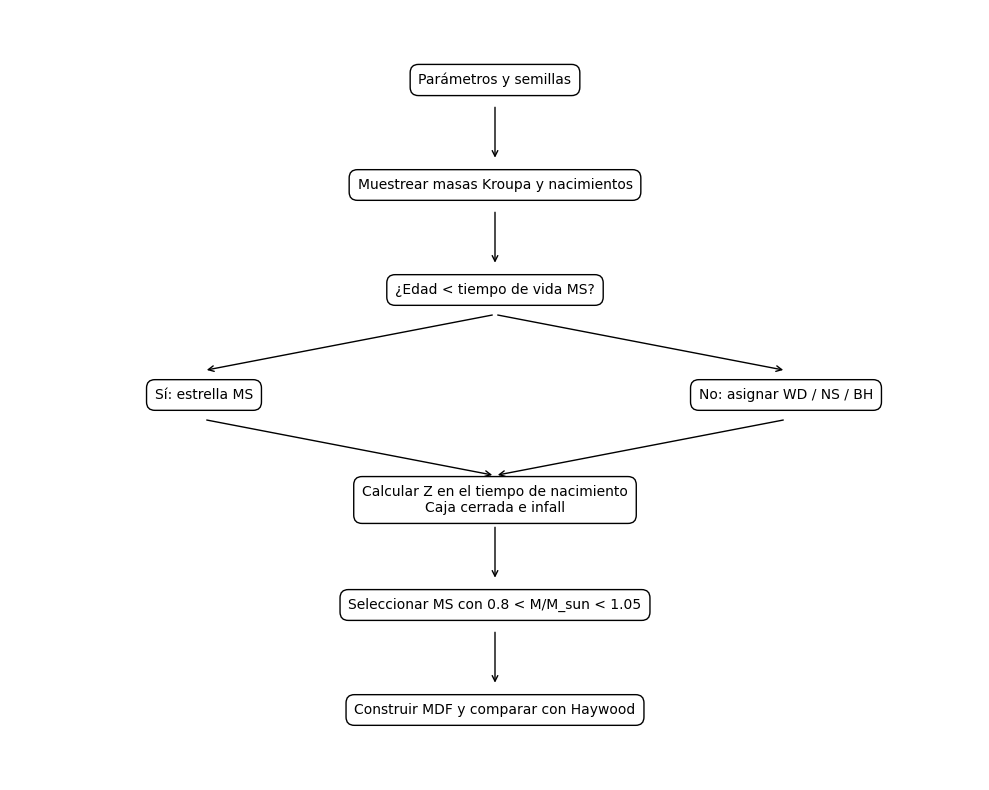

In [69]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 11)
ax.axis("off")

boxes = {
    "start": (5, 10, "Parámetros y semillas"),
    "sample": (5, 8.5, "Muestrear masas Kroupa y nacimientos"),
    "decision": (5, 7, "¿Edad < tiempo de vida MS?"),
    "ms": (2, 5.5, "Sí: estrella MS"),
    "rem": (8, 5.5, "No: asignar WD / NS / BH"),
    "chem": (5, 4, "Calcular Z en el tiempo de nacimiento\nCaja cerrada e infall"),
    "selection": (5, 2.5, "Seleccionar MS con 0.8 < M/M_sun < 1.05"),
    "comparison": (5, 1, "Construir MDF y comparar con Haywood"),
}

for x, y, text in boxes.values():
    ax.text(
        x, y, text,
        ha="center", va="center", fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor="black",
        ),
    )

connections = [
    ("start", "sample"),
    ("sample", "decision"),
    ("decision", "ms"),
    ("decision", "rem"),
    ("ms", "chem"),
    ("rem", "chem"),
    ("chem", "selection"),
    ("selection", "comparison"),
]

for source, target in connections:
    x1, y1, _ = boxes[source]
    x2, y2, _ = boxes[target]

    ax.annotate(
        "",
        xy=(x2, y2+0.35),
        xytext=(x1, y1-0.35),
        arrowprops=dict(arrowstyle="->", color="black"),
    )

plt.tight_layout()
plt.savefig(OUT / "diagrama_flujo.png", dpi=200)
fig.savefig(OUT / "diagrama_flujo.pdf", bbox_inches="tight")
plt.show()

## 13. Limitaciones y trabajo pendiente

Trabajamos con una sola zona, mezcla instantánea y formación estelar constante durante 10 Gyr. El enriquecimiento se calcula con un rendimiento efectivo, sin sumar los aportes de cada estrella.

Asignamos remanentes directamente después de la secuencia principal. Las relaciones usadas no dependen aquí de Z y tienen las transiciones aproximadas descritas en el apartado 5.

Comparamos [M/H] con [Fe/H] de forma aproximada. No calculamos elementos por separado ni retardos de supernovas Ia. La muestra de Haywood tiene una selección distinta de la simulada y no incluye las correcciones posteriores del artículo.

Los modelos de infall son pruebas con parámetros fijos, sin ajuste a las observaciones ni obligación de terminar con metalicidad solar. La dispersión entre semillas solo mide ruido Monte Carlo.

